1. Data Import and Exploration

In [5]:
import pandas as pd
from pathlib import Path 

data_folder = Path("/Users/cameroni/retail-customer-analytics/data/raw/")

excel_file = list(data_folder.glob("*.xlsx"))[0]

print(excel_file)

/Users/cameroni/retail-customer-analytics/data/raw/online_retail_II.xlsx


In [6]:
print(excel_file.exists())

True


In [7]:
import pandas as pd

#read the Excel Workbook
excel = pd.ExcelFile(excel_file)

#Display the worksheet names
print(excel.sheet_names)

['Year 2009-2010', 'Year 2010-2011']


In [8]:
df_1 = pd.read_excel(excel_file, sheet_name=0)
df_2 = pd.read_excel(excel_file, sheet_name=1)

#combine
df = pd.concat([df_1, df_2], ignore_index= True)
print("Dataset successfully loaded!")

Dataset successfully loaded!


In [9]:
print("Dataset Dimensions:", df.shape)
df.head()

Dataset Dimensions: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [11]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [12]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394029,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [13]:
negatives = (df["Quantity"] < 0).sum()
invalid_p = (df["Price"] <= 0).sum()
missing_c = df["Customer ID"].isnull().sum()
print("Negative Quantities:", negatives)
print("Zero or Negative Prices:", invalid_p)
print("Missing Customer IDs:", missing_c)

Negative Quantities: 22950
Zero or Negative Prices: 6207
Missing Customer IDs: 243007


In [16]:
#records with negative quantities
df[df["Quantity"] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [18]:
cancelled = 0
for invoice in df["Invoice"]:
    if str(invoice).startswith("C"):
        cancelled = cancelled + 1
print("Cancelled transactions:", cancelled)


Cancelled transactions: 19494


In [19]:
duplicates = df.duplicated().sum()
print("Duplicate records:", duplicates)

Duplicate records: 34335


2. Data Cleaning 

In [21]:
df_clean = df.copy()
#Remove rows with no customer ID
df_clean = df_clean.dropna(subset=["Customer ID"])
#Remove negative quantities and zero quantities
df_clean = df_clean[df_clean["Quantity"] > 0]
#Remove negative prices and zero prices
df_clean = df_clean[df_clean["Price"] > 0]
#Remove duplicate rows
df_clean = df_clean.drop_duplicates()
#How many rows?
print(len(df_clean))

779425


In [22]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]
df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [23]:
df_clean.to_csv("/Users/cameroni/retail-customer-analytics/data/cleaned_retail.csv", index = False)

print("File saved!")

File saved!


In [24]:
print("Total rows:", len(df_clean))
print("Total revenue:", df_clean["Revenue"].sum())

Total rows: 779425
Total revenue: 17374804.268


3. SQL Database and Customer Analysis

In [26]:
import sqlite3
#Connect Python and SQL
conn = sqlite3.connect("/Users/cameroni/retail-customer-analytics/data/retail.db")
#Add clean data
df_clean.to_sql("sales", conn, if_exists = "replace", index = False)

779425

In [27]:
import pandas as pd
query = "SELECT COUNT(*) FROM sales"
pd.read_sql(query, conn)

,COUNT(*)
0,779425


In [30]:
query = """
SELECT
    "Customer ID",
    SUM(Revenue) AS Total_Spent
FROM Sales
GROUP BY "Customer ID"
ORDER BY Total_Spent DESC
LIMIT 10
"""
pd.read_sql(query, conn)

,Customer ID,Total_Spent
0,18102.0,580987.04
1,14646.0,528602.52
2,14156.0,313437.62
3,14911.0,291420.81
4,17450.0,244784.25
5,13694.0,195640.69
6,17511.0,172132.87
7,16446.0,168472.50
8,16684.0,147142.77
9,12415.0,144458.37


In [31]:
query = """
SELECT *
FROM sales
"""
pd.read_sql(query, conn)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.40
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.00
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.80
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.00
...,...,...,...,...,...,...,...,...,...
779420,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60
779421,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
779422,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60
779423,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85


In [34]:
query = """
SELECT
    "Customer ID",
    COUNT(DISTINCT Invoice) AS Total_Orders
FROM sales
GROUP BY "Customer ID"
ORDER BY Total_Orders DESC
LIMIT 10
"""
pd.read_sql(query, conn)

,Customer ID,Total_Orders
0,14911.0,398
1,12748.0,336
2,17841.0,211
3,15311.0,208
4,13089.0,203
5,14606.0,192
6,14156.0,156
7,17850.0,155
8,14646.0,151
9,18102.0,145


In [37]:
query = """
SELECT
    "Customer ID",
    COUNT(DISTINCT Invoice) AS Total_Orders,
    SUM(Revenue) As Total_Spent
FROM sales
GROUP BY "Customer ID"
ORDER BY Total_Spent DESC
LIMIT 10
"""

pd.read_sql(query, conn)

    

,Customer ID,Total_Orders,Total_Spent
0,18102.0,145,580987.04
1,14646.0,151,528602.52
2,14156.0,156,313437.62
3,14911.0,398,291420.81
4,17450.0,51,244784.25
5,13694.0,143,195640.69
6,17511.0,60,172132.87
7,16446.0,2,168472.50
8,16684.0,55,147142.77
9,12415.0,28,144458.37


In [38]:
query = """
SELECT
"Customer ID",
COUNT(DISTINCT Invoice) AS Total_Orders,
SUM(Revenue) AS Total_Spent,
ROUND(SUM(Revenue) / COUNT(DISTINCT Invoice), 2) As Average_Order_Value
FROM sales
GROUP BY "Customer ID"
ORDER BY Total_Spent DESC
LIMIT 10
"""

pd.read_sql(query, conn)



,Customer ID,Total_Orders,Total_Spent,Average_Order_Value
0,18102.0,145,580987.04,4006.81
1,14646.0,151,528602.52,3500.68
2,14156.0,156,313437.62,2009.22
3,14911.0,398,291420.81,732.21
4,17450.0,51,244784.25,4799.69
5,13694.0,143,195640.69,1368.12
6,17511.0,60,172132.87,2868.88
7,16446.0,2,168472.50,84236.25
8,16684.0,55,147142.77,2675.32
9,12415.0,28,144458.37,5159.23


In [39]:
query = """
SELECT 
"Customer ID",
MAX(InvoiceDate) AS Last_Purchase
FROM sales
GROUP BY "Customer ID"
LIMIT 10
"""
pd.read_sql(query, conn)

,Customer ID,Last_Purchase
0,12346.0,2011-01-18 10:01:00
1,12347.0,2011-12-07 15:52:00
2,12348.0,2011-09-25 13:13:00
3,12349.0,2011-11-21 09:51:00
4,12350.0,2011-02-02 16:01:00
5,12351.0,2010-11-29 15:23:00
6,12352.0,2011-11-03 14:37:00
7,12353.0,2011-05-19 17:47:00
8,12354.0,2011-04-21 13:11:00
9,12355.0,2011-05-09 13:49:00


In [42]:
query = """
SELECT 
MAX(InvoiceDate) AS Latest_Date
FROM sales
"""

pd.read_sql(query, conn)

,Latest_Date
0,2011-12-09 12:50:00


4. Recency, Frequency, and Monetary Customer Segmentation

In [45]:
query = """
SELECT
"Customer ID",
MAX(InvoiceDate) AS Last_Purchase,
CAST(
    julianday('2011-12-10') - julianday(MAX(InvoiceDate))
    AS INTEGER
    ) AS Recency
FROM sales
GROUP BY "Customer ID"
LIMIT 10
"""

pd.read_sql(query, conn)


,Customer ID,Last_Purchase,Recency
0,12346.0,2011-01-18 10:01:00,325
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,18
4,12350.0,2011-02-02 16:01:00,310
5,12351.0,2010-11-29 15:23:00,375
6,12352.0,2011-11-03 14:37:00,36
7,12353.0,2011-05-19 17:47:00,204
8,12354.0,2011-04-21 13:11:00,232
9,12355.0,2011-05-09 13:49:00,214


In [46]:
query = """
SELECT
"Customer ID",
CAST(
    julianday('2011-12-10') - julianday(MAX(InvoiceDate))
    AS INTEGER
    ) AS Recency,
COUNT (DISTINCT Invoice) AS Frequency,
ROUND(SUM(Revenue), 2) AS Monetary
FROM sales
GROUP BY "Customer ID"
"""

rfm = pd.read_sql(query, conn)
rfm.head(10)


,Customer ID,Recency,Frequency,Monetary
0,12346.0,325,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,18,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2849.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


In [48]:
print("Total customers:", len(rfm))


Total customers: 5878


In [49]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,15315.313542,200.866791,6.289384,2955.904092
std,1715.572666,209.353961,13.009406,14440.852686
min,12346.000000,0.000000,1.000000,2.950000
25%,13833.250000,25.000000,1.000000,342.280000
50%,15314.500000,95.000000,3.000000,867.740000
75%,16797.750000,379.000000,7.000000,2248.305000
max,18287.000000,738.000000,398.000000,580987.040000


5. Exploratory Data Visualization

Matplotlib is building the font cache; this may take a moment.


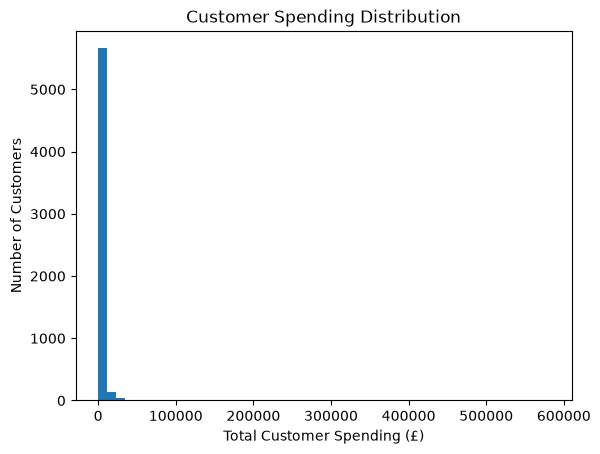

In [50]:
import matplotlib.pyplot as plt
plt.hist(rfm["Monetary"], bins=50)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Customer Spending (£)")
plt.ylabel("Number of Customers")

plt.show()

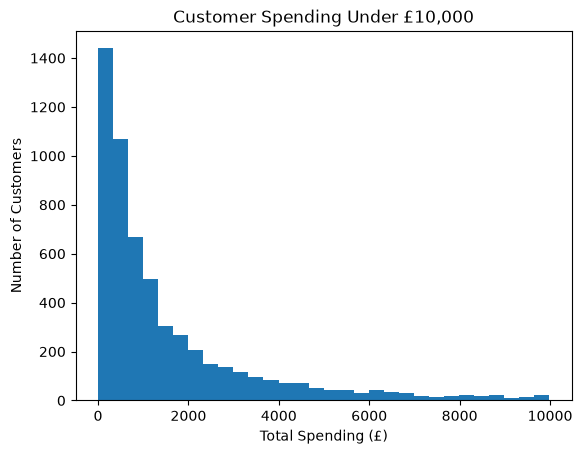

In [53]:
import matplotlib.pyplot as plt

small_customers = rfm[rfm["Monetary"] < 10000]

plt.hist(small_customers["Monetary"], bins=30)

plt.title("Customer Spending Under £10,000")
plt.xlabel("Total Spending (£)")
plt.ylabel("Number of Customers")

plt.show()

In [55]:
def spending_group(amount):
    if amount < 1000:
        return "Low"
    elif amount < 5000:
        return "Medium"
    else:
        return "High"
rfm ["Spending_Group"] = rfm["Monetary"].apply(spending_group)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Spending_Group
0,12346.0,325,12,77556.46,High
1,12347.0,2,8,4921.53,Medium
2,12348.0,75,5,2019.40,Medium
3,12349.0,18,4,4428.69,Medium
4,12350.0,310,1,334.40,Low


In [56]:
rfm["Spending_Group"].value_counts()

Spending_Group
Low       3173
Medium    2060
High       645
Name: count, dtype: int64

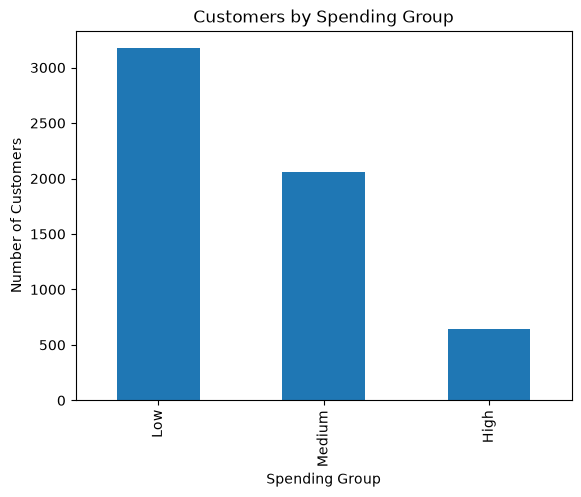

In [114]:
rfm["Spending_Group"].value_counts().plot(kind="bar")

plt.title("Customers by Spending Group")
plt.xlabel("Spending Group")
plt.ylabel("Number of Customers")

plt.show()                                          

                                    

In [59]:
rfm.groupby("Spending_Group")["Frequency"].mean()

Spending_Group
High      25.700775
Low        2.008194
Medium     6.805825
Name: Frequency, dtype: float64

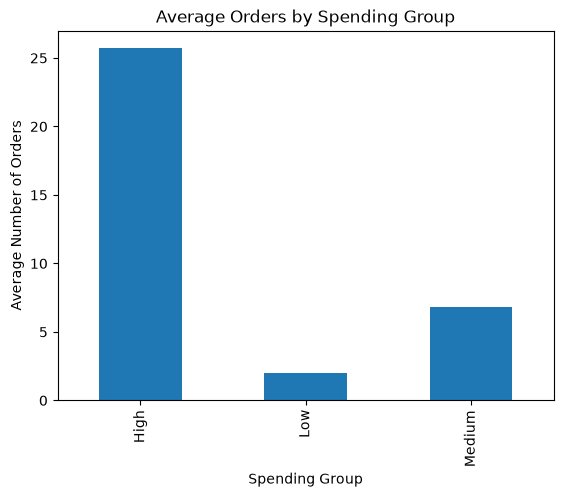

In [60]:
average_orders = rfm.groupby("Spending_Group")["Frequency"].mean()

average_orders.plot(kind="bar")

plt.title("Average Orders by Spending Group")
plt.xlabel("Spending Group")
plt.ylabel("Average Number of Orders")

plt.show()

In [61]:
revenue = rfm.groupby("Spending_Group")["Monetary"].sum()

print(revenue)

Spending_Group
High      11405400.09
Low        1334802.46
Medium     4634601.70
Name: Monetary, dtype: float64


In [62]:
percentage = revenue / revenue.sum() * 100

print(percentage.round(2))

Spending_Group
High      65.64
Low        7.68
Medium    26.67
Name: Monetary, dtype: float64


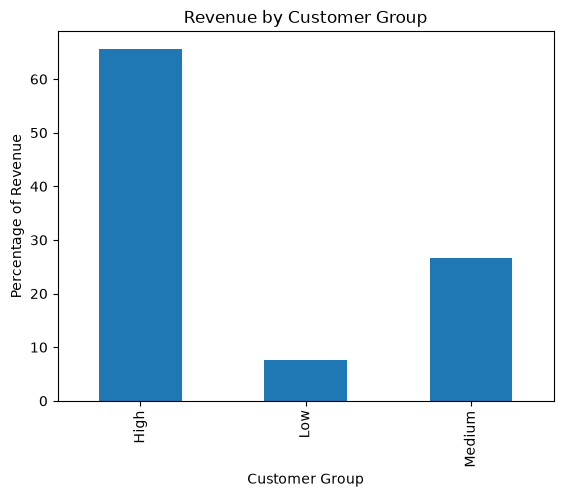

In [63]:
percentage.plot(kind="bar")

plt.title("Revenue by Customer Group")
plt.xlabel("Customer Group")
plt.ylabel("Percentage of Revenue")

plt.show()


6. Customer Retention Analysis

In [64]:
repeat_customers = rfm[rfm["Frequency"] > 1]
print("Repeat customers:", len(repeat_customers))

Repeat customers: 4255


In [65]:
repeat_rate = len(repeat_customers)/ len(rfm) * 100

print("Repeat purchase rate:", round(repeat_rate, 2), "%")

Repeat purchase rate: 72.39 %


7. Machine Learning Data Preperation

In [67]:
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

past = df_clean[df_clean["InvoiceDate"] < "2011-09-10"]

future = df_clean[df_clean["InvoiceDate"] >= "2011-09-10"]

print("Historical records:", len(past))
print("Future records:", len(future))

Historical records: 620572
Future records: 158853


In [68]:
future_customers = future["Customer ID"].unique()

print("Future customers:", len(future_customers))

Future customers: 2889


In [69]:
customers = past["Customer ID"].unique()

model_data = pd.DataFrame(customers, columns = ["Customer ID"])

model_data["Purchased_Again"] = model_data["Customer ID"].isin(future_customers).astype(int)

model_data.head()

,Customer ID,Purchased_Again
0,13085.0,0
1,13078.0,1
2,15362.0,0
3,18102.0,1
4,12682.0,1


In [71]:
model_data["Purchased_Again"].value_counts()

Purchased_Again
0    2989
1    2292
Name: count, dtype: int64

In [72]:
past_rfm = past.groupby("Customer ID").agg(
    Last_Purchase = ("InvoiceDate", "max"),
    Frequency = ("Invoice", "nunique"),
    Monetary = ("Revenue", "sum")
)

past_rfm.head()

,Last_Purchase,Frequency,Monetary
Customer ID,,,
12346.0,2011-01-18 10:01:00,12,77556.46
12347.0,2011-08-02 08:48:00,6,3402.39
12348.0,2011-04-05 10:47:00,4,1709.40
12349.0,2010-10-28 08:23:00,3,2671.14
12350.0,2011-02-02 16:01:00,1,334.40


In [73]:
past_rfm["Recency"] = (
    pd.Timestamp("2011-09-10") - past_rfm["Last_Purchase"]
).dt.days
past_rfm.head()

,Last_Purchase,Frequency,Monetary,Recency
Customer ID,,,,
12346.0,2011-01-18 10:01:00,12,77556.46,234
12347.0,2011-08-02 08:48:00,6,3402.39,38
12348.0,2011-04-05 10:47:00,4,1709.40,157
12349.0,2010-10-28 08:23:00,3,2671.14,316
12350.0,2011-02-02 16:01:00,1,334.40,219


In [74]:
model_data = model_data.merge(
    past_rfm,
    on="Customer ID"
)

model_data.head()

,Customer ID,Purchased_Again,Last_Purchase,Frequency,Monetary,Recency
0,13085.0,0,2011-07-05 12:11:00,8,2433.28,66
1,13078.0,1,2011-08-25 10:16:00,46,23307.27,15
2,15362.0,0,2010-09-17 10:37:00,2,613.08,357
3,18102.0,1,2011-09-02 11:53:00,112,456780.49,7
4,12682.0,1,2011-08-31 12:18:00,41,18890.32,9


In [75]:
X = model_data[["Recency", "Frequency", "Monetary"]]
y = model_data["Purchased_Again"]

In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

8. Logistic Regression

In [79]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Model Trained!")
    
    

Model Trained!


In [80]:
from sklearn.metrics import accuracy_score

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print("Model accuracy:", round(accuracy * 100, 2), "%")

Model accuracy: 71.05 %


In [81]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predictions))


              precision    recall  f1-score   support

           0       0.74      0.75      0.75       598
           1       0.67      0.66      0.66       459

    accuracy                           0.71      1057
   macro avg       0.71      0.70      0.70      1057
weighted avg       0.71      0.71      0.71      1057



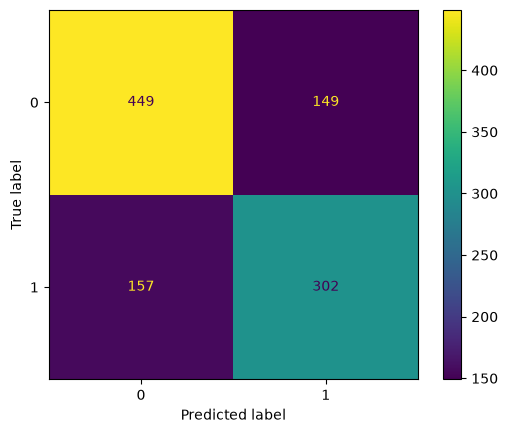

In [82]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, predictions)

plt.show()

9. Random Forest

In [83]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
forest.fit(X_train, y_train)

print("Random Forest Trained!")

Random Forest Trained!


In [84]:
forest_predictions = forest.predict(X_test)

forest_accuracy = accuracy_score(y_test, forest_predictions)

print("Random Forest Accuracy:", round(forest_accuracy * 100, 2), "%")

Random Forest Accuracy: 71.43 %


In [85]:
print(classification_report(y_test, forest_predictions))

              precision    recall  f1-score   support

           0       0.73      0.78      0.75       598
           1       0.69      0.63      0.66       459

    accuracy                           0.71      1057
   macro avg       0.71      0.70      0.71      1057
weighted avg       0.71      0.71      0.71      1057



In [86]:
Importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": forest.feature_importances_
})
print(Importance)

     Feature  Importance
0    Recency    0.423063
1  Frequency    0.143647
2   Monetary    0.433290


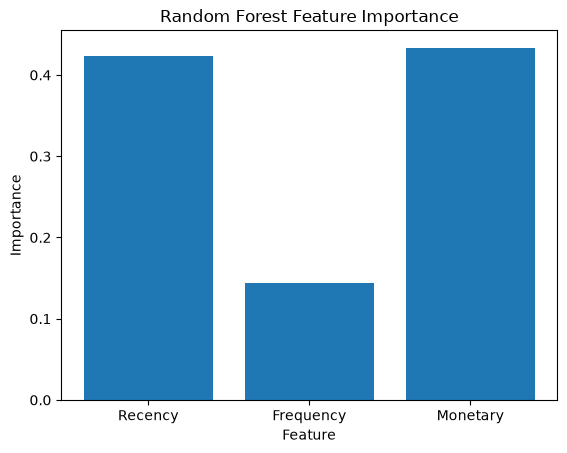

In [90]:
plt.bar(Importance["Feature"], Importance["Importance"])

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")

plt.show()

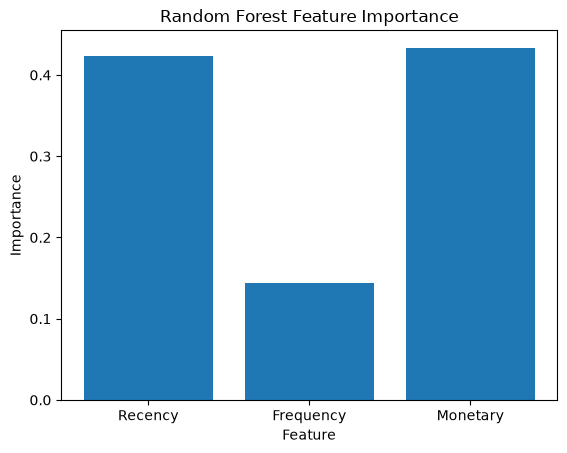

In [94]:
plt.bar(Importance["Feature"], Importance["Importance"])

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")

plt.savefig("/Users/cameroni/retail-customer-analytics/visualization/feature_importance.png")

plt.show()

In [97]:
from pathlib import Path 
Path("/Users/cameroni/retail-customer-analytics/reports").mkdir(exist_ok=True)
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [71.05, 71.43],
    "Percision": [0.67, 0.69],
    "Recall": [0.66, 0.63],
    "F1_score": [0.66, 0.66]
        })
results.to_csv("/Users/cameroni/retail-customer-analytics/reports/model_results.csv", index=False)

results
    


,Model,Accuracy,Percision,Recall,F1_score
0,Logistic Regression,71.05,0.67,0.66,0.66
1,Random Forest,71.43,0.69,0.63,0.66


In [99]:
print("First Transaction:", df_clean["InvoiceDate"].min())
print("Last Transaction:", df_clean["InvoiceDate"].max())

First Transaction: 2009-12-01 07:45:00
Last Transaction: 2011-12-09 12:50:00


10. Model Evaluation

In [100]:
past2 = df_clean[df_clean["InvoiceDate"] < "2011-07-01"]

future2 = df_clean[
    (df_clean["InvoiceDate"] >= "2011-07-01") &
    (df_clean["InvoiceDate"] < "2011-09-29")
    ]
print("Historical Records:", len(past2))
print("Future Records:", len(future2))

Historical Records: 557398
Future Records: 89356


In [101]:
future_customers2 = future2["Customer ID"].unique()

customers2 = past2["Customer ID"].unique()

model_data2 = pd.DataFrame(
    customers2,
    columns = ["Customer ID"]
)

model_data2["Purchased_Again"] = (
    model_data2["Customer ID"].isin(future_customers2).astype(int)
)

model_data2.head()

,Customer ID,Purchased_Again
0,13085.0,1
1,13078.0,1
2,15362.0,0
3,18102.0,1
4,12682.0,1


In [103]:
past_rfm2 = past2.groupby("Customer ID").agg(
    Last_Purchase = ("InvoiceDate", "max"),
    Frequency = ("Invoice", "nunique"),
    Monetary = ("Revenue", "sum")
)

past_rfm2["Recency"] = (
    pd.Timestamp("2011-07-01") - past_rfm2["Last_Purchase"]
).dt.days
    
    

In [104]:
model_data2 = model_data2.merge(
    past_rfm2,
    on= "Customer ID"
)

model_data2.head()

,Customer ID,Purchased_Again,Last_Purchase,Frequency,Monetary,Recency
0,13085.0,1,2011-02-17 13:57:00,7,2295.30,133
1,13078.0,1,2011-06-29 12:37:00,43,21633.70,1
2,15362.0,0,2010-09-17 10:37:00,2,613.08,286
3,18102.0,1,2011-06-14 11:31:00,105,427931.29,16
4,12682.0,1,2011-06-15 10:22:00,34,16732.78,15


In [106]:
print(model_data2["Purchased_Again"].value_counts())

Purchased_Again
0    3325
1    1716
Name: count, dtype: int64


In [107]:
X2 = model_data2[["Recency", "Frequency", "Monetary"]]

Y2 = model_data2["Purchased_Again"]

In [109]:
predictions2 = model.predict(X2)

print("Logistic Regression:")
print(classification_report(Y2, predictions2))

Logistic Regression:
              precision    recall  f1-score   support

           0       0.84      0.75      0.79      3325
           1       0.60      0.73      0.66      1716

    accuracy                           0.74      5041
   macro avg       0.72      0.74      0.73      5041
weighted avg       0.76      0.74      0.75      5041



In [110]:
forest_prediction2 = forest.predict(X2)

print("Random Forest:")
print(classification_report(Y2, forest_prediction2))

Random Forest:
              precision    recall  f1-score   support

           0       0.82      0.72      0.77      3325
           1       0.56      0.70      0.62      1716

    accuracy                           0.71      5041
   macro avg       0.69      0.71      0.70      5041
weighted avg       0.73      0.71      0.72      5041



In [111]:
features = ["Recency", "Frequency", "Monetary"]

X_train_time = model_data2[features]
y_train_time = model_data2["Purchased_Again"]

X_test_time = model_data2[features]
y_test_time = model_data2["Purchased_Again"]





In [113]:
time_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

time_model.fit(X_train_time, y_train_time)

time_predictions = time_model.predict(X_test_time)

print(classification_report(y_test_time, time_predictions))

              precision    recall  f1-score   support

           0       0.78      0.90      0.84      3325
           1       0.72      0.51      0.60      1716

    accuracy                           0.77      5041
   macro avg       0.75      0.70      0.72      5041
weighted avg       0.76      0.77      0.75      5041



Conclusions